# Smart Home Energy Consumption Prediction
## Notebook 1: Data cleaning and exploratory analysis
**Aim:** predict appliance energy use for the next 10-minute interval using readings already available.

Read the markdown, then run cells from top to bottom. All code is here; no project modules or dashboard are needed.
This notebook covers PDF stages **1–7**. Notebook 2 covers **8–12** and contains the prediction demonstration.

## 1. Problem definition and use case
A household resident could use a short-term forecast to anticipate a high-consumption interval and decide whether to delay a flexible appliance. Inputs are recent appliance use, time, lighting, indoor conditions and weather. The output is **energy in Wh for the next 10 minutes**, not power in W and not a daily energy bill.

**Assumption:** a meter reading at time t is available after its interval has finished. We predict t+10 minutes; no future sensor readings are used. This is a rolling one-step forecast, so new observed meter readings become available between successive predictions. It is not a forecast of an entire future day from one starting point.

**Scope and impact:** a local notebook demonstration for one house. Forecasting might inform scheduling; actual cost reductions need a separate controlled study. The dataset does not identify individual appliances or prove which action saves energy.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA = Path('data')  # Open this notebook from the project folder.
assert (DATA / 'energydata_complete.csv').exists(), 'Run from the folder containing data/.'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 4)
pd.set_option('display.max_columns', 32)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)

Python: 3.14.8 | pandas: 3.1.0


## 2. Data acquisition and understanding
**Source:** Candanedo, L. (2017), *Appliances Energy Prediction*, UCI Machine Learning Repository. [Dataset and documentation](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction), [DOI](https://doi.org/10.24432/C5VC8G).

**Ownership/use:** UCI credits Luis Candanedo; distribution is under **CC BY 4.0**, which permits reuse with attribution. The source study is by L. Candanedo, V. Feldheim and D. Deramaix (2017), *Data driven prediction models of energy use of appliances in a low-energy house*, Energy and Buildings 140.

**Collection:** about 4.5 months in one low-energy house in Belgium. ZigBee temperature/humidity readings were averaged into 10-minute intervals; energy was logged with m-bus meters. Airport weather was merged by timestamp; some hourly weather measurements were interpolated. Consequently weather values are not guaranteed to be genuine real-time observations, limiting a live forecast based on this dataset.

| Columns | Meaning | Unit |
|---|---|---|
| date | Observation timestamp | date/time |
| Appliances, lights | Appliance / lighting energy in an interval | Wh |
| T1–T9 | Kitchen, living room, laundry, office, bathroom, outside north, ironing room, teenager room, parents room | °C |
| RH_1–RH_9 | Relative humidity at the corresponding locations | % |
| T_out, Tdewpoint | Airport outdoor / dew-point temperature | °C |
| RH_out | Airport relative humidity | % |
| Press_mm_hg | Air pressure | mm Hg |
| Windspeed, Visibility | Wind speed / visibility | m/s, km |
| rv1, rv2 | Artificial random test variables | none |

The original target is `Appliances`. For forecasting we shift it by one row to create `next_appliances_Wh`. Size and types are checked below rather than assumed.

In [2]:
raw = pd.read_csv(DATA / 'energydata_complete.csv')
print('Original rows and columns:', raw.shape)
display(raw.head())
display(raw.dtypes.rename('dtype').to_frame())
print('Missing values:', int(raw.isna().sum().sum()))
print('Exact duplicate records:', int(raw.duplicated().sum()))

Original rows and columns: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


,dtype
date,str
Appliances,int64
lights,int64
T1,float64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_3,float64
T4,float64


Missing values: 0
Exact duplicate records: 0


## 3. Data preparation
Parse timestamps, check numeric formats, remove exact duplicate records if present, and sort by time. Conflicting duplicate timestamps require inspection rather than arbitrary deletion. Check a regular 10-minute interval before creating next-row targets.

Invalid physical values are turned into missing values; later the model imputes them using **training data only**. Negative temperatures can be valid. A high energy reading alone is not a reason to delete a row.

In [3]:
clean = raw.drop_duplicates().copy()
clean['date'] = pd.to_datetime(clean['date'], errors='raise')
for col in clean.columns.drop('date'):
    clean[col] = pd.to_numeric(clean[col], errors='raise')
clean = clean.sort_values('date').reset_index(drop=True)
assert not clean['date'].duplicated().any(), 'Inspect conflicting duplicate timestamps.'
intervals = clean['date'].diff().dropna()
display(intervals.value_counts().rename('interval_count').to_frame())
assert intervals.eq(pd.Timedelta(minutes=10)).all(), 'Handle time gaps before shifting targets.'

invalid = pd.DataFrame(False, index=clean.index, columns=clean.columns.drop('date'))
for col in ['Appliances', 'lights', 'Windspeed', 'Visibility', 'Press_mm_hg']:
    invalid[col] = clean[col] < 0
for col in [c for c in clean if c.startswith('RH_')]:
    invalid[col] = ~clean[col].between(0, 100) & clean[col].notna()
print('Invalid values by column:')
display(invalid.sum().rename('invalid_count').to_frame().T)
clean[invalid.columns] = clean[invalid.columns].mask(invalid)
assert clean['Appliances'].notna().all(), 'Missing energy requires an explicit target policy.'
print('rv1 equals rv2:', clean['rv1'].equals(clean['rv2']))
clean = clean.drop(columns=['rv1', 'rv2'])
clean.to_csv(DATA / 'clean_energydata.csv', index=False)
print('Before:', raw.shape, '| After:', clean.shape)
print('Date range:', clean['date'].min(), 'to', clean['date'].max())
print('Remaining missing values:', int(clean.isna().sum().sum()))

,interval_count
date,
0 days 00:10:00,19734


Invalid values by column:


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
invalid_count,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


rv1 equals rv2: True


Before: (19735, 29) | After: (19735, 27)
Date range: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Remaining missing values: 0


**Decision:** remove the two random columns because the dataset documentation identifies them as artificial variables, not physical predictors. No energy spikes are removed. The printed before/after counts show exactly what changed.

## 4–5. Preprocessing and balancing
This is **regression**, so class balancing and SMOTE are not applicable. We inspect the continuous target distribution and later measure errors on high-consumption intervals. We do not resample the observations.

Linear Regression will use median imputation and standard scaling fitted inside a training pipeline. Random Forest uses training-only median imputation and does not require scaling. There are no string categories after removing the timestamp from model inputs: time is encoded explicitly below.

For analytical EDA, use only the earliest 70% of records. Later observations remain unavailable for feature or model choices. Full-data checks above concern structural validity only.

In [4]:
# Align EDA's boundary with the model-ready table, which loses 5 warm-up rows and 1 final row.
model_rows = len(clean) - 6
train_end = int(0.70 * model_rows)
eda = clean.iloc[5:5 + train_end].copy()
display(eda[['Appliances', 'T1', 'RH_1', 'T_out', 'RH_out']].describe().round(2))
q1, q3 = eda['Appliances'].quantile([0.25, 0.75])
iqr_limit = q3 + 1.5 * (q3 - q1)
peak_threshold = eda['Appliances'].quantile(0.95)
print(f'Training upper IQR fence: {iqr_limit:.1f} Wh')
print(f'Values above fence: {(eda.Appliances > iqr_limit).sum()} (retained)')
print(f'Training 95th percentile: {peak_threshold:.1f} Wh')
print(f'Target skewness: {eda.Appliances.skew():.2f}')

,Appliances,T1,RH_1,T_out,RH_out
count,13810.00,13810.00,13810.00,13810.00,13810.00
mean,98.79,21.07,40.40,5.72,82.58
std,106.87,1.24,3.55,4.15,12.32
min,10.00,16.79,31.43,-5.00,44.00
25%,50.00,20.29,37.70,2.83,74.33
50%,60.00,21.20,40.09,5.67,86.00
75%,100.00,22.00,43.13,8.80,92.16
max,1080.00,24.10,63.36,19.70,100.00


Training upper IQR fence: 175.0 Wh
Values above fence: 1609 (retained)
Training 95th percentile: 340.0 Wh
Target skewness: 3.25


## 6. Exploratory data analysis
### Question A: Is consumption concentrated at low values, with occasional spikes?
The histogram describes the distribution; the daily average shows the longer-term pattern. The IQR rule flags unusual readings but cannot tell whether they are sensor errors. Keeping plausible spikes preserves the events that an energy forecast should handle.

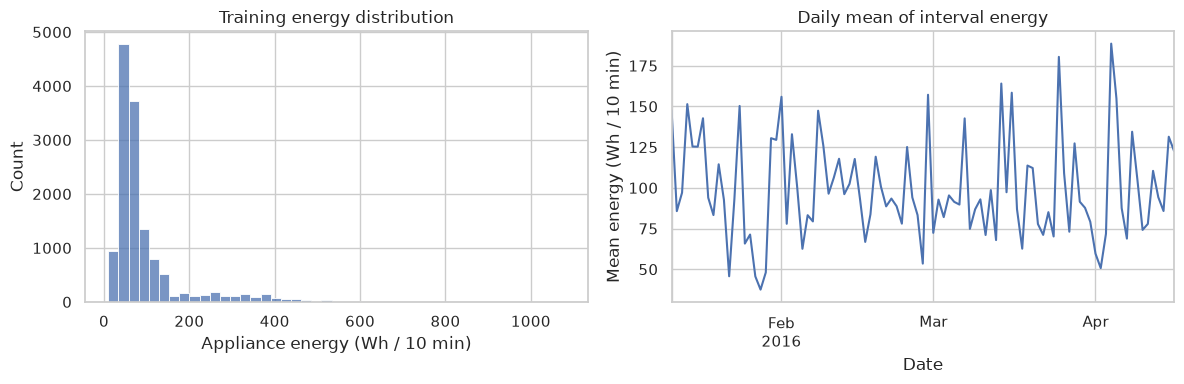

Median 60.0 Wh; mean 98.8 Wh; max 1080.0 Wh.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(eda['Appliances'], bins=45, ax=axes[0])
axes[0].set(xlabel='Appliance energy (Wh / 10 min)', title='Training energy distribution')
eda.set_index('date')['Appliances'].resample('D').mean().plot(ax=axes[1])
axes[1].set(ylabel='Mean energy (Wh / 10 min)', xlabel='Date', title='Daily mean of interval energy')
plt.tight_layout()
plt.show()
print(f'Median {eda.Appliances.median():.1f} Wh; mean {eda.Appliances.mean():.1f} Wh; max {eda.Appliances.max():.1f} Wh.')

### Question B: Does time of day or day of week matter?
These are averages across the training period, not a rule that every day follows. They justify trying simple calendar features; chronological validation will decide whether those features help prediction.

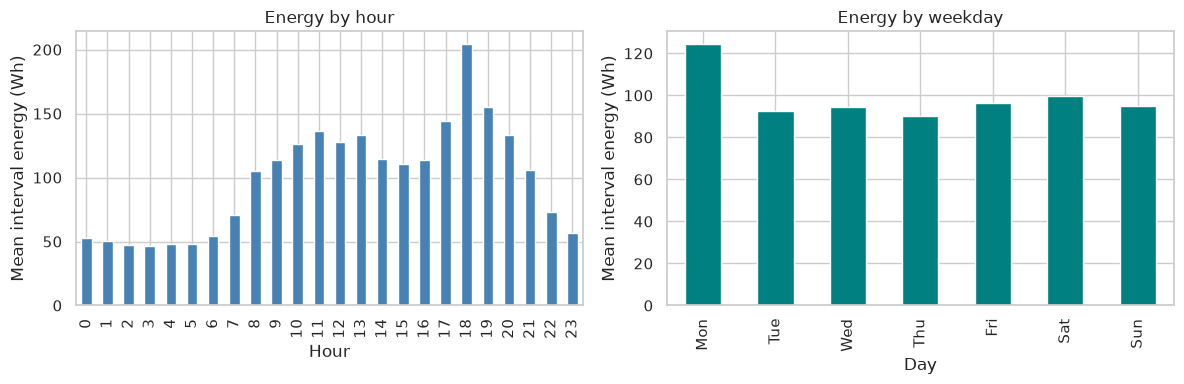

Highest average hour: 18:00 (204.1 Wh per interval).
Lowest average hour: 03:00 (46.6 Wh per interval).


In [6]:
hourly = eda.groupby(eda.date.dt.hour)['Appliances'].mean()
weekly = eda.groupby(eda.date.dt.day_of_week)['Appliances'].mean().reindex(range(7))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hourly.plot(kind='bar', ax=axes[0], color='steelblue')
weekly.set_axis(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']).plot(kind='bar', ax=axes[1], color='teal')
axes[0].set(xlabel='Hour', ylabel='Mean interval energy (Wh)', title='Energy by hour')
axes[1].set(xlabel='Day', ylabel='Mean interval energy (Wh)', title='Energy by weekday')
plt.tight_layout()
plt.show()
print(f'Highest average hour: {hourly.idxmax():02d}:00 ({hourly.max():.1f} Wh per interval).')
print(f'Lowest average hour: {hourly.idxmin():02d}:00 ({hourly.min():.1f} Wh per interval).')

### Question C: How do indoor conditions and weather relate to energy?
Scatterplots show spread as well as association. A weak linear correlation does not exclude a nonlinear relationship. Observational relationships cannot establish that changing temperature or humidity will reduce consumption.

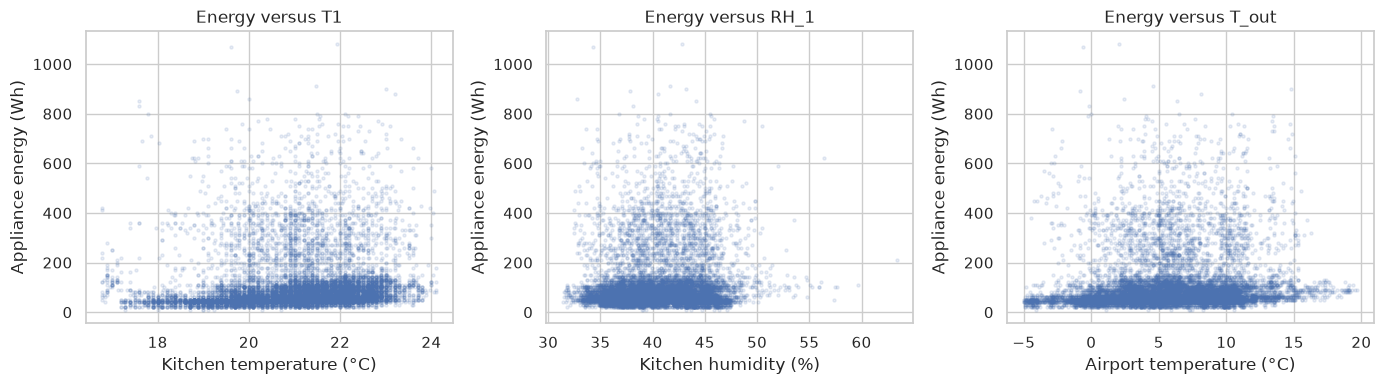

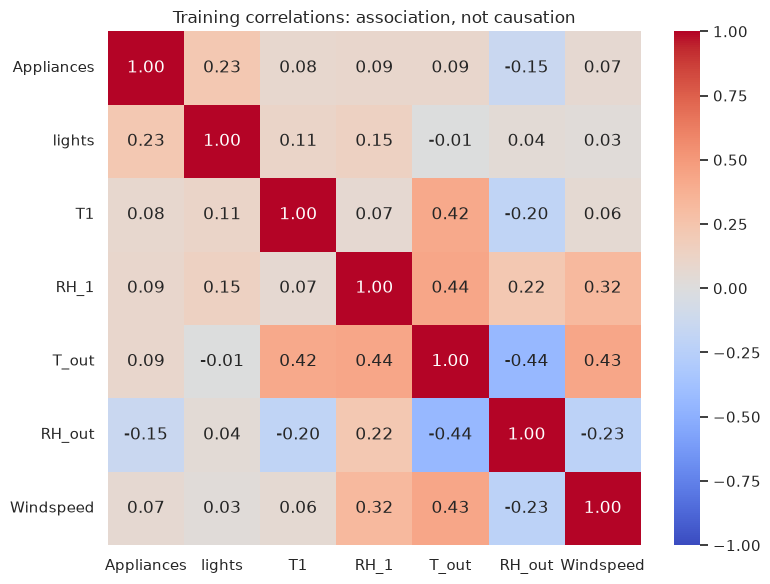

,correlation_with_energy
lights,0.226511
T_out,0.092871
RH_1,0.089633
T1,0.083829
Windspeed,0.066028
RH_out,-0.147043


Decision: keep a small sensor set; compare adding energy history on validation in Notebook 2.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, label in zip(axes, ['T1', 'RH_1', 'T_out'], ['Kitchen temperature (°C)', 'Kitchen humidity (%)', 'Airport temperature (°C)']):
    ax.scatter(eda[col], eda['Appliances'], s=5, alpha=0.12)
    ax.set(xlabel=label, ylabel='Appliance energy (Wh)', title=f'Energy versus {col}')
plt.tight_layout()
plt.show()
cols = ['Appliances', 'lights', 'T1', 'RH_1', 'T_out', 'RH_out', 'Windspeed']
corr = eda[cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Training correlations: association, not causation')
plt.tight_layout()
plt.show()
display(corr['Appliances'].drop('Appliances').sort_values(ascending=False).rename('correlation_with_energy').to_frame())
print('Decision: keep a small sensor set; compare adding energy history on validation in Notebook 2.')

### Question D: What does a high-consumption event look like?
Show a window around the largest training spike. Abrupt changes can be hard to predict from the previous reading. Notebook 2 tests this directly through residuals, peak errors and the worst predictions.

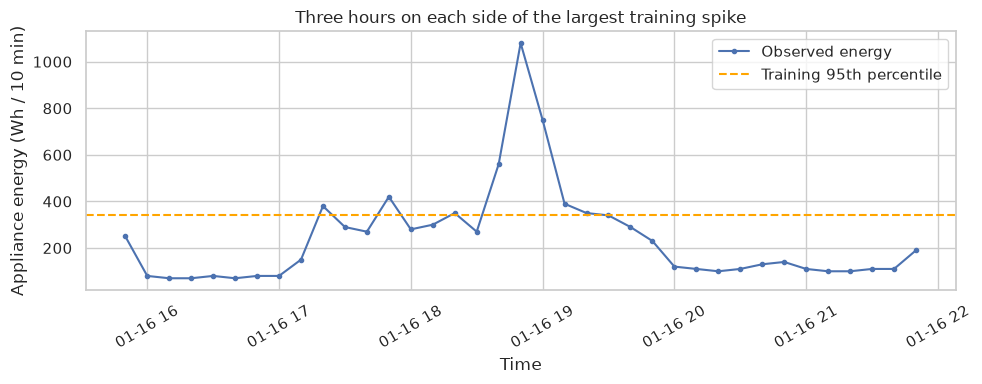

In [8]:
peak_index = eda['Appliances'].idxmax()
window = clean.loc[max(eda.index.min(), peak_index - 18):min(eda.index.max(), peak_index + 18)]
plt.plot(window['date'], window['Appliances'], marker='.', label='Observed energy')
plt.axhline(peak_threshold, linestyle='--', color='orange', label='Training 95th percentile')
plt.xlabel('Time')
plt.ylabel('Appliance energy (Wh / 10 min)')
plt.title('Three hours on each side of the largest training spike')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 7. Feature engineering and selection
Keep the model small and explainable:

- `current_Wh`: latest observed appliance energy, the strongest simple persistence signal.
- `lag_10m_Wh`: reading one interval before the current reading.
- `mean_1h_Wh`: mean of six readings ending at the current time, to smooth short-term variation.
- `lights`, `T1`, `RH_1`, `T_out`, `RH_out`: a small representative sensor set. Other rooms/weather variables are excluded to reduce complexity; this is a deliberate scope choice, not proof they are useless.
- `hour_sin`, `hour_cos`: encode next interval's hour around a circle so 23:50 and 00:00 remain close.
- `is_weekend`: known calendar information.

Every feature is known by time t, except future calendar time which is known in advance. Rolling windows are not centered. We shift **only the target** into the future. The first five rows lack a complete one-hour history; the final row lacks a future label. Their exclusion is structural, not outlier removal.

In [9]:
features = pd.DataFrame({'date': clean['date']})
features['target_time'] = clean['date'] + pd.Timedelta(minutes=10)
features['current_Wh'] = clean['Appliances']
features['lag_10m_Wh'] = clean['Appliances'].shift(1)
features['mean_1h_Wh'] = clean['Appliances'].rolling(6, min_periods=6).mean()
for col in ['lights', 'T1', 'RH_1', 'T_out', 'RH_out']:
    features[col] = clean[col]
hour = features['target_time'].dt.hour + features['target_time'].dt.minute / 60
features['hour_sin'] = np.sin(2 * np.pi * hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * hour / 24)
features['is_weekend'] = (features['target_time'].dt.day_of_week >= 5).astype(int)
features['next_appliances_Wh'] = clean['Appliances'].shift(-1)
model_data = features.iloc[5:-1].reset_index(drop=True)
assert len(model_data) == model_rows
assert model_data['target_time'].eq(model_data['date'] + pd.Timedelta(minutes=10)).all()
assert np.isclose(model_data.loc[0, 'mean_1h_Wh'], clean['Appliances'].iloc[:6].mean())
assert model_data.loc[0, 'next_appliances_Wh'] == clean.loc[6, 'Appliances']
model_data.to_csv(DATA / 'model_ready_energydata.csv', index=False)
print('Clean sensor table:', clean.shape)
print('Model table:', model_data.shape, '(2 timestamps, 11 predictors, 1 target)')
print('Rows excluded for history/future label:', len(clean) - len(model_data))
display(model_data.head())

Clean sensor table: (19735, 27)
Model table: (19729, 14) (2 timestamps, 11 predictors, 1 target)
Rows excluded for history/future label: 6


,date,target_time,current_Wh,lag_10m_Wh,mean_1h_Wh,lights,T1,RH_1,T_out,RH_out,hour_sin,hour_cos,is_weekend,next_appliances_Wh
0,2016-01-11 17:50:00,2016-01-11 18:00:00,50,60.0,55.000000,40,19.890000,46.026667,6.016667,92.000000,-1.000000,-1.836970e-16,0,60.0
1,2016-01-11 18:00:00,2016-01-11 18:10:00,60,50.0,55.000000,50,19.890000,45.766667,5.900000,92.000000,-0.999048,4.361939e-02,0,60.0
2,2016-01-11 18:10:00,2016-01-11 18:20:00,60,60.0,55.000000,50,19.856667,45.560000,5.916667,91.833333,-0.996195,8.715574e-02,0,60.0
3,2016-01-11 18:20:00,2016-01-11 18:30:00,60,60.0,56.666667,40,19.790000,45.597500,5.933333,91.666667,-0.991445,1.305262e-01,0,70.0
4,2016-01-11 18:30:00,2016-01-11 18:40:00,70,60.0,60.000000,40,19.856667,46.090000,5.950000,91.500000,-0.984808,1.736482e-01,0,230.0


## What to explain in the viva
1. This is regression because the target is a numerical energy reading.
2. We checked missing values, duplicates, physical consistency and time intervals before modelling.
3. We removed documented random variables and retained plausible energy spikes.
4. Balancing classes does not apply; rare peaks still deserve a separate error check.
5. The cleaned CSV contains sensor records; the model-ready CSV adds historical features and the next-interval target.
6. Continue with **02_Model_Training_and_Evaluation.ipynb**. Its outputs provide the actual evidence for model selection.